# Product Pricing A/B Test


**Business objective:** Find a delivery-fee setup that generates more orders while maintaining revenue.

**Revenue formula:** `revenue = order_value * 20% + delivery_fee`




In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.formula.api as smf
from statsmodels.stats.anova import anova_lm

df = pd.read_excel("Procduct Pricing.xlsx")
df.columns = df.columns.str.strip().str.lower()
df["date"] = pd.to_datetime(df["date"], errors="coerce")
df["fee_present"] = df["delivery_fee"] > 0
df["time_period"] = np.select([df.hour < 12, df.hour > 18],
                              ["Morning (<12)", "Evening (>18)"],
                              default="Midday (12–18)")
control = df[df.variant_transaction == "Control"].copy()
test = df[df.variant_transaction == "Test"].copy()

print("Dataset shape:", df.shape)
print("Missing values:\\n", df.isna().sum())
print("Duplicate rows:", df.duplicated().sum())
print("Revenue formula max difference:",
      (df.revenue - (0.20*df.order_value + df.delivery_fee)).abs().max())

def welch(a, b):
    return stats.ttest_ind(a, b, equal_var=False, nan_policy="omit")

display(df.head())


Matplotlib is building the font cache; this may take a moment.


Dataset shape: (18006, 9)
Missing values:\n date                   0
code                   0
variant_transaction    0
order_value            0
hour                   0
delivery_fee           0
revenue                0
fee_present            0
time_period            0
dtype: int64
Duplicate rows: 0
Revenue formula max difference: 7.105427357601002e-15


,date,code,variant_transaction,order_value,hour,delivery_fee,revenue,fee_present,time_period
0,2021-07-01,1,Control,10.0,21,2.29,4.29,True,Evening (>18)
1,2021-07-01,2,Control,12.0,21,2.29,4.69,True,Evening (>18)
2,2021-07-01,3,Control,17.0,10,2.29,5.69,True,Morning (<12)
3,2021-07-01,4,Control,24.0,13,2.29,7.09,True,Midday (12–18)
4,2021-07-01,5,Control,36.0,17,2.29,9.49,True,Midday (12–18)


## KPI Summary

Orders = transaction count; AOV = mean order_value; delivery fee = mean delivery_fee; total revenue = sum(revenue); revenue per order = mean(revenue).

In [2]:
kpis = df.groupby("variant_transaction").agg(
    orders=("code","count"),
    average_order_value=("order_value","mean"),
    average_delivery_fee=("delivery_fee","mean"),
    revenue_per_order=("revenue","mean"),
    total_revenue=("revenue","sum"),
    order_value_sd=("order_value","std")
)
display(kpis)


,orders,average_order_value,average_delivery_fee,revenue_per_order,total_revenue,order_value_sd
variant_transaction,,,,,,
Control,8232,29.324351,2.290000,8.154870,67130.892,23.109259
Test,9774,31.901928,1.949362,8.329747,81414.948,24.672022


## Question 1. What is the distribution of order_value across different hours of the day? Are there any specific hours where the order values are significantly higher or lower?

**Answer:** Hourly order values vary. Highest overall mean AOV: 09:00 (35.55), followed by 15:00 (34.52) and 13:00 (34.24); lowest: 08:00 (26.82). One-way ANOVA across hours: F=20.05, p=9.06e-48, showing at least one hourly mean differs. Post-hoc comparisons with multiplicity correction are required to identify exact hour pairs.

,count,mean,median,std
hour,,,,
9,540,35.545667,25.715,30.518546
15,1146,34.515916,24.990,28.812146
13,984,34.244695,29.460,28.826851
12,1152,33.800260,25.340,29.705748
14,1056,33.314091,25.080,22.861852
11,966,32.843230,28.550,21.410806
17,1176,32.707398,25.400,21.602625
20,1482,32.644049,23.750,31.326377
19,1212,30.404851,25.380,19.568942


One-way ANOVA across hours: F_onewayResult(statistic=np.float64(20.053065115841118), pvalue=np.float64(9.056780478107721e-48))


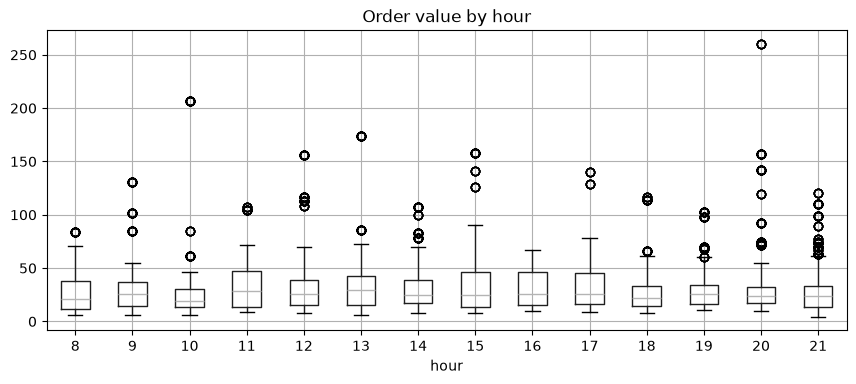

In [3]:
hourly = df.groupby("hour").order_value.agg(["count","mean","median","std"])
display(hourly.sort_values("mean",ascending=False))
anova_hour = stats.f_oneway(*[g.order_value.dropna().values for _,g in df.groupby("hour")])
print("One-way ANOVA across hours:", anova_hour)
df.boxplot(column="order_value",by="hour",figsize=(10,4)); plt.title("Order value by hour"); plt.suptitle(""); plt.show()


## Question 2. How does the revenue distribution differ between transactions in the morning (e.g., before noon) and evening (e.g., after 6 PM)?

**Answer:** Morning (<12:00) mean revenue/order is 7.90; evening (>18:00) is 8.14, 3.0% higher. Morning AOV is 29.21; evening AOV is 29.79. These are per-order averages; total revenue also depends on transaction volume.

In [4]:
period = df.groupby(["variant_transaction","time_period"]).agg(
    orders=("code","count"), mean_revenue=("revenue","mean"),
    total_revenue=("revenue","sum"), mean_aov=("order_value","mean"))
display(period)
print("Overall morning mean revenue:",df.loc[df.hour<12,"revenue"].mean())
print("Overall evening mean revenue:",df.loc[df.hour>18,"revenue"].mean())


orders  mean_revenue  total_revenue  \
variant_transaction time_period                                           
Control             Evening (>18)     2538      8.010548      20330.772   
                    Midday (12–18)    3726      8.622828      32128.656   
                    Morning (<12)     1968      7.455012      14671.464   
Test                Evening (>18)     3018      8.249952      24898.356   
                    Midday (12–18)    4080      8.452950      34488.036   
                    Morning (<12)     2676      8.231897      22028.556   

                                     mean_aov  
variant_transaction time_period                
Control             Evening (>18)   28.602742  
                    Midday (12–18)  31.664138  
                    Morning (<12)   25.825061  
Test                Evening (>18)   30.795487  
                    Midday (12–18)  32.855412  
                    Morning (<12)   31.696031

Overall morning mean revenue: 7.9026744186046525
Overall evening mean revenue: 8.140591792656586


## Question 3. How does the delivery_fee impact the revenue? Are there any patterns where higher or lower fees correlate with revenue changes?

**Answer:** Revenue = 0.20 × order_value + delivery_fee. Holding order value constant, a higher fee adds directly to revenue. In observed Test transactions, fee and revenue have Pearson r=-0.581 (p<0.001), a negative association because high-fee records tend to have lower order values in this sample. Zero/low-fee records have much higher AOV. This is confounded by order/customer mix and is not causal evidence of fee elasticity.

In [5]:
fee_summary = df.groupby(["variant_transaction","delivery_fee"]).agg(
    orders=("code","count"),mean_aov=("order_value","mean"),
    mean_revenue=("revenue","mean"),total_revenue=("revenue","sum"))
display(fee_summary)
test_fee_corr = stats.pearsonr(test.delivery_fee,test.revenue)
print("Treatment fee vs revenue Pearson correlation:",test_fee_corr)


orders   mean_aov  mean_revenue  \
variant_transaction delivery_fee                                    
Control             2.29            8232  29.324351      8.154870   
Test                0.00            2340  62.743513     12.548703   
                    0.29             192  61.371250     12.564250   
                    1.99              72  27.293333      7.448667   
                    2.49            3402  20.717584      6.633517   
                    2.59            2304  21.333437      6.856688   
                    2.89             984  21.330000      7.156000   
                    2.99              24  26.950000      8.380000   
                    3.29             456  21.868947      7.663789   

                                  total_revenue  
variant_transaction delivery_fee                 
Control             2.29              67130.892  
Test                0.00              29363.964  
                    0.29               2412.336  
                    1.99                536.304  
                    2.49              22567.224  
                    2.59              15797.808  
                    2.89               7041.504  
                    2.99                201.120  
                    3.29               3494.688

Treatment fee vs revenue Pearson correlation: PearsonRResult(statistic=np.float64(-0.5805698676961892), pvalue=np.float64(0.0))


## Question 4. Is there a statistically significant difference in revenue between the Control and Treatment groups?

**Answer:** Yes. Mean revenue/order is 8.15 Control vs 8.33 Test. Welch t=-2.644, p=0.00821. Reject equal means at α=0.05. Test mean is 2.1% higher. Assignment method and exposure denominators are undocumented, so this is an observed difference, not causal proof.

In [6]:
result = welch(control.revenue,test.revenue)
print("Control mean revenue/order:",control.revenue.mean())
print("Test mean revenue/order:",test.revenue.mean())
print("Welch t-test:",result)


Control mean revenue/order: 8.15487026239067
Test mean revenue/order: 8.329747084100676
Welch t-test: TtestResult(statistic=np.float64(-2.6436367868975195), pvalue=np.float64(0.008209697064686593), df=np.float64(16757.973156332184))


## Question 5. How does the variant_transaction (Control vs. Treatment) affect the order_value? Is there evidence that one variant leads to higher order values?

**Answer:** Test AOV is 31.90 vs Control 29.32, 8.8% higher. Welch t=-7.229, p=5.08e-13; statistically significant. Differences in customer mix, promotions or assignment may also contribute.

In [7]:
result = welch(control.order_value,test.order_value)
print("Control AOV:",control.order_value.mean(),"Test AOV:",test.order_value.mean())
print("Welch t-test:",result)


Control AOV: 29.324351311953354 Test AOV: 31.901927562922033
Welch t-test: TtestResult(statistic=np.float64(-7.228535656905845), pvalue=np.float64(5.080122026369406e-13), df=np.float64(17802.279924288916))


## Question 6. Does the variant_transaction influence the delivery_fee charged? Is there a significant difference between the groups?

**Answer:** Yes. Control has a fixed fee of 2.29; Test has multiple fee levels and mean fee 1.95. Welch t=29.113, p=8.99e-179. The difference is significant and confirms different fee distributions, but does not identify the best fee policy.

In [8]:
result = welch(control.delivery_fee,test.delivery_fee)
print("Control mean fee:",control.delivery_fee.mean(),"Test mean fee:",test.delivery_fee.mean())
print("Welch t-test:",result)


Control mean fee: 2.29 Test mean fee: 1.9493615715162673
Welch t-test: TtestResult(statistic=np.float64(29.113191782865712), pvalue=np.float64(8.990415468791051e-179), df=np.float64(9773.0))


c:\Users\DELL\AppData\Local\Programs\Python\Python313\Lib\site-packages\scipy\stats\_axis_nan_policy.py:601: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  res = hypotest_fun_out(*samples, **kwds)


## Question 7. Does the time of day (hour) impact the effectiveness of the treatment? Are there certain times where the Treatment group outperforms the Control group in terms of revenue?

**Answer:** A two-way ANOVA of revenue by variant, hour and their interaction finds a significant variant-by-hour interaction: F=39.08, p=8.42e-99. Test mean revenue is higher at hours 8, 10, 12, 14, 16, 18, 19, 20; Control leads at 9, 11, 13, 15, 17, 21. Hour-specific winners are exploratory; correct for multiple comparisons.

,sum_sq,df,F,PR(>F)
C(variant_transaction),187.758035,1.0,10.203918,1.403844e-03
C(hour),5786.797680,13.0,24.191531,7.880723e-59
C(variant_transaction):C(hour),9347.908877,13.0,39.078648,8.423061e-99
Residual,330805.687391,17978.0,NaN,NaN


variant_transaction,Control,Test
hour,,
8,6.689275,7.943660
9,9.496368,8.766154
10,6.642099,8.666782
11,9.161167,8.170119
12,7.625368,9.771649
13,9.622541,8.457089
14,8.569275,9.033108
15,10.752805,7.949667
16,7.426741,8.261856


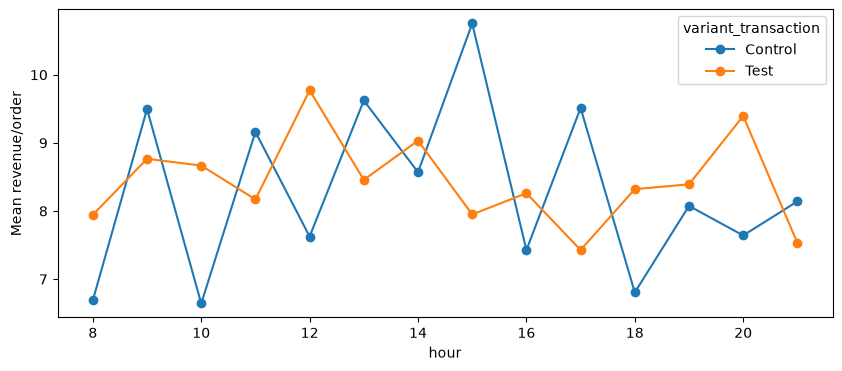

In [9]:
model = smf.ols("revenue ~ C(variant_transaction) * C(hour)",data=df).fit()
anova_table = anova_lm(model,typ=2)
display(anova_table)
hourly_rev = df.groupby(["hour","variant_transaction"]).revenue.mean().unstack()
display(hourly_rev)
hourly_rev.plot(marker="o",figsize=(10,4)); plt.ylabel("Mean revenue/order"); plt.show()


## Question 8. Is there greater variance in order_value within the Control or Treatment group? What does this imply about the consistency of the order values in each group?

**Answer:** Test has higher order-value SD (24.67) than Control (23.11). Levene statistic=9.295, p=0.0023; variance differs significantly. Test orders are more dispersed/less consistent in absolute terms, possibly reflecting a wider mix of baskets or cohorts.

In [10]:
print("Control order value SD:",control.order_value.std())
print("Test order value SD:",test.order_value.std())
print("Levene test:",stats.levene(control.order_value,test.order_value,center="median"))


Control order value SD: 23.109259270224726
Test order value SD: 24.6720222770241
Levene test: LeveneResult(statistic=np.float64(9.295227730974602), pvalue=np.float64(0.0023008501670807586))


## Question 9. How does the order value vary by hour of the day? Are there specific hours where the order values are significantly higher or lower across the control and test groups?

**Answer:** Hourly AOV differs by group. Test mean AOV is higher at hours 8, 10, 12, 14, 16, 18, 19, 20; Control is higher at 9, 11, 13, 15, 17, 21. Overall highest mean AOV is at 09:00 (35.55); lowest at 08:00 (26.82). Overall ANOVA p=9.06e-48; post-hoc corrected tests needed for exact pairs.

variant_transaction,Control,Test
hour,,
8,21.996376,30.305437
9,36.031842,35.190385
10,21.760494,32.611494
11,34.355833,31.944653
12,26.676842,40.776804
13,36.662703,32.256556
14,31.396373,35.957432
15,42.314026,29.248772
16,25.683704,32.684536


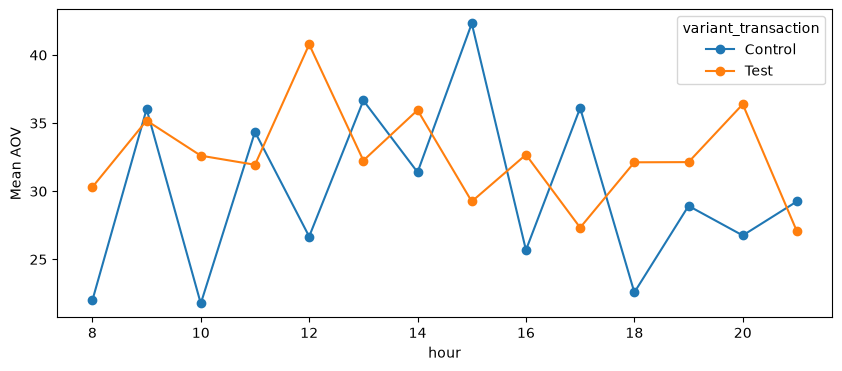

Overall hourly ANOVA: F_onewayResult(statistic=np.float64(20.053065115841118), pvalue=np.float64(9.056780478107721e-48))


In [11]:
hourly_aov = df.groupby(["hour","variant_transaction"]).order_value.mean().unstack()
display(hourly_aov)
hourly_aov.plot(marker="o",figsize=(10,4)); plt.ylabel("Mean AOV"); plt.show()
print("Overall hourly ANOVA:",stats.f_oneway(*[g.order_value.values for _,g in df.groupby("hour")]))


## Question 10. Does the presence or absence of a delivery fee significantly affect the total revenue in the test and control groups?

**Answer:** In Test, zero-fee transactions: 2,340, mean revenue 12.55, total 29,363.96. Fee-paying Test transactions: 7,434, mean revenue 7.00, total 52,050.98. Welch comparison of per-order revenue is significant (p<0.001). Control has no zero-fee transactions. Fee-free Test orders have much higher AOV, so cohort mix confounds the comparison.

In [12]:
fee_presence = df.groupby(["variant_transaction","fee_present"]).agg(
    orders=("code","count"),mean_revenue=("revenue","mean"),
    total_revenue=("revenue","sum"),mean_aov=("order_value","mean"))
display(fee_presence)
print("Within Test, fee vs no-fee revenue Welch test:",
      welch(test.loc[test.fee_present,"revenue"],test.loc[~test.fee_present,"revenue"]))


orders  mean_revenue  total_revenue  \
variant_transaction fee_present                                        
Control             True           8232      8.154870      67130.892   
Test                False          2340     12.548703      29363.964   
                    True           7434      7.001747      52050.984   

                                  mean_aov  
variant_transaction fee_present             
Control             True         29.324351  
Test                False        62.743513  
                    True         22.193923

Within Test, fee vs no-fee revenue Welch test: TtestResult(statistic=np.float64(-44.17864026801898), pvalue=np.float64(0.0), df=np.float64(2521.213620343301))


## Question 11. Is there a significant correlation between order value and revenue? How does this relationship differ between the control and test groups?

**Answer:** Pearson correlation between order value and revenue is 1.0000 in Control and 0.9816 in Test (both p<0.001). Control is almost perfectly correlated because fee is fixed at 2.29 and revenue is a linear function of order value. Test correlation is slightly weaker because delivery fee varies.

In [13]:
for name,group in df.groupby("variant_transaction"):
    print(name,stats.pearsonr(group.order_value,group.revenue))


Control PearsonRResult(statistic=np.float64(0.9999999999999997), pvalue=np.float64(0.0))
Test PearsonRResult(statistic=np.float64(0.9816149617499053), pvalue=np.float64(0.0))


## Question 12. Does the time of day impact the revenue generated in the control and test groups? Are there specific hours where one group outperforms the other in terms of revenue?

**Answer:** Hourly revenue profile varies. Variant-by-hour interaction is significant (F=39.08, p=8.42e-99). Test average revenue is higher at hours 8, 10, 12, 14, 16, 18, 19, 20; Control leads at 9, 11, 13, 15, 17, 21. Apply multiple-comparison correction before acting on individual hours.

In [14]:
hourly_rev = df.groupby(["hour","variant_transaction"]).revenue.mean().unstack()
display(hourly_rev)
model = smf.ols("revenue ~ C(variant_transaction) * C(hour)",data=df).fit()
display(anova_lm(model,typ=2))


variant_transaction,Control,Test
hour,,
8,6.689275,7.943660
9,9.496368,8.766154
10,6.642099,8.666782
11,9.161167,8.170119
12,7.625368,9.771649
13,9.622541,8.457089
14,8.569275,9.033108
15,10.752805,7.949667
16,7.426741,8.261856


,sum_sq,df,F,PR(>F)
C(variant_transaction),187.758035,1.0,10.203918,1.403844e-03
C(hour),5786.797680,13.0,24.191531,7.880723e-59
C(variant_transaction):C(hour),9347.908877,13.0,39.078648,8.423061e-99
Residual,330805.687391,17978.0,NaN,NaN


## Question 13. Is there a statistically significant difference in the average order values between the control and test groups?

**Answer:** Yes. Average order value is 29.32 Control and 31.90 Test. Welch t=-7.229, p=5.08e-13; statistically significant. Test AOV is 8.8% higher. This question repeats the core AOV comparison and is answered separately as requested.

In [15]:
result = welch(control.order_value,test.order_value)
print("Control mean AOV:",control.order_value.mean())
print("Test mean AOV:",test.order_value.mean())
print("Welch test:",result)


Control mean AOV: 29.324351311953354
Test mean AOV: 31.901927562922033
Welch test: TtestResult(statistic=np.float64(-7.228535656905845), pvalue=np.float64(5.080122026369406e-13), df=np.float64(17802.279924288916))


## Question 14. Does the presence or absence of a delivery fee influence the order value? How does this vary between the control and test groups?

**Answer:** In Test, zero-fee transactions have mean AOV 62.74; fee-paying transactions have mean AOV 22.19. Welch t=-64.387, p<0.001. Control has only fee-paying orders, so fee presence cannot be compared within Control. This association may reflect promotions or customer/order selection, not fee causality.

In [16]:
print("Test AOV by fee presence:")
display(test.groupby("fee_present").order_value.agg(["count","mean","std"]))
print("Welch test, fee vs no-fee AOV:",
      welch(test.loc[test.fee_present,"order_value"],test.loc[~test.fee_present,"order_value"]))


Test AOV by fee presence:


,count,mean,std
fee_present,,,
False,2340,62.743513,29.800594
True,7434,22.193923,11.277034


Welch test, fee vs no-fee AOV: TtestResult(statistic=np.float64(-64.38664608369467), pvalue=np.float64(0.0), df=np.float64(2552.979617681201))


## Question 15. Is there greater variance in the order value within the control group compared to the test group? What does this indicate about the consistency of order values?

**Answer:** No. Control SD is 23.11; Test SD is 24.67. Levene p=0.0023, so Test has significantly greater variance and less consistent/more dispersed order values. This repeats Question 8 in the assignment and is answered independently here.

In [17]:
print("Control variance:",control.order_value.var(),"SD:",control.order_value.std())
print("Test variance:",test.order_value.var(),"SD:",test.order_value.std())
print("Levene test:",stats.levene(control.order_value,test.order_value,center="median"))


Control variance: 534.0378640184674 SD: 23.109259270224726
Test variance: 608.7086832379734 SD: 24.6720222770241
Levene test: LeveneResult(statistic=np.float64(9.295227730974602), pvalue=np.float64(0.0023008501670807586))


## Overall conclusion and management recommendation

The Test group has higher observed order volume and total revenue, but it is not possible to identify one winning delivery fee from the pooled Test results. Run a follow-up randomized experiment with a fixed control fee and clearly defined treatment price(s). Measure orders/conversion per eligible user and contribution margin per eligible user, alongside AOV, commission revenue, delivery-fee revenue, delivery costs, cancellations, refunds and repeat purchase. Predefine sample size, duration, primary metric and guardrails.